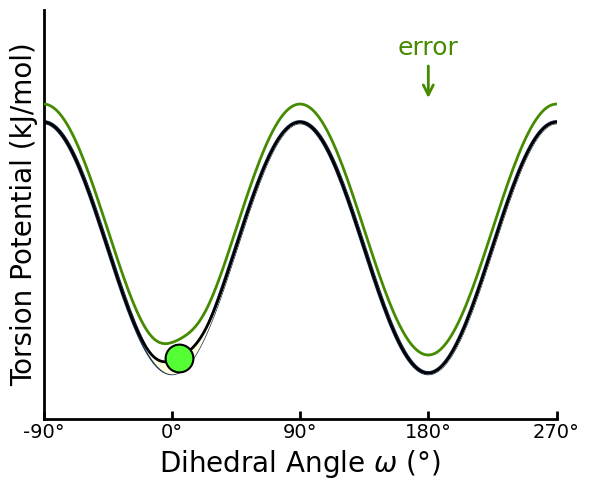

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
# Define the True Free Energy Surface (Dihedral Potential)
def true_fes(omega_deg):
    # Convert degrees back to radians just for the mathematical formula
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

# Dihedral angles in degrees (-180 to 180)
x_grid = np.linspace(-180, 180, 200)
fes_true = true_fes(x_grid)

# Simulation parameters
n_steps = 16000
dt = 0.01
kT = 2.49       

# Scaling factor to keep the physical dynamics identical to the radian version
mobility = (180.0 / np.pi)**2

# Metadynamics parameters
sigma = 11.5        # Gaussian width in degrees (equivalent to 0.2 rad)
w_initial = 1.5     # Initial height of Gaussian (kJ/mol)
delta_T = 2.0       # Well-tempered bias factor parameter
deposition_stride = 5

# Arrays to keep track of state
x_pos = -90.0       # Start in the left minimum (-90 degrees)
bias_potential = np.zeros_like(x_grid)
history_x = []
history_bias = []

# --- 2. Run Simplified Simulation ---
for step in range(n_steps):
    # Calculate forces (derivative of FES + Bias)
    dx = 0.5 # Small step in degrees for finite difference
    force_true = -(true_fes(x_pos + dx) - true_fes(x_pos - dx)) / (2 * dx)
    
    # Force from bias (interpolated from grid)
    idx = (np.abs(x_grid - x_pos)).argmin()
    if idx > 0 and idx < len(x_grid)-1:
        force_bias = -(bias_potential[idx+1] - bias_potential[idx-1]) / (x_grid[idx+1] - x_grid[idx-1])
    else:
        force_bias = 0
        
    total_force = force_true + force_bias
    
    # Update position (Overdamped Langevin dynamics)
    # Scaled by mobility so the particle explores the degree grid properly
    noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    x_pos = x_pos + total_force * mobility * dt + noise
    
    # Periodic boundary conditions to keep it on the dihedral grid (-180 to 180)
    if x_pos > 180.0:
        x_pos -= 360.0
    elif x_pos < -180.0:
        x_pos += 360.0
    
    # Add Gaussian bias periodically
    if step % deposition_stride == 0:
        current_bias_at_x = np.interp(x_pos, x_grid, bias_potential)
        w_current = w_initial * np.exp(-current_bias_at_x / (kT * delta_T))
        
        # Add to grid using periodic distance in degrees
        dist = np.abs(x_grid - x_pos)
        dist = np.minimum(dist, 360.0 - dist) # Shortest path on a 360-degree circle
        gaussian = w_current * np.exp(-dist**2 / (2 * sigma**2))
        bias_potential += gaussian
        
    history_x.append(x_pos)
    history_bias.append(bias_potential.copy())

# --- 3. Create Animation ---
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
ax.set_facecolor('white')

# Axis styling adjusted for degrees
ax.set_xlim(-180, 180)
ax.set_ylim(-5, 40)
ax.set_xlabel(r'Dihedral Angle $\omega$ (°)', fontsize=20, color='black')
ax.set_ylabel('Torsion Potential (kJ/mol)', fontsize=20, color='black')
ax.tick_params(colors='black', direction='in', length=6, width=2)

# Set exact tick marks for x-axis
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xticklabels(['-90°', '0°', '90°', '180°', '270°'], fontsize=14)

# ---> REMOVE Y-TICKS HERE <---
ax.set_yticks([]) 

ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Plot elements
# 1. Base line representing the unbiased energy surface
line_base, = ax.plot(x_grid, fes_true, color='#1a335c', lw=3, zorder=1)

# 2. Dynamic elements updated by the animation
fill_bias = ax.fill_between(x_grid, fes_true, fes_true, color='#ffffe0', alpha=1.0, zorder=2)
line_eff_fes, = ax.plot(x_grid, fes_true, color='black', lw=2, zorder=3)
line_error, = ax.plot(x_grid, fes_true + 2, color='#458b00', lw=2, zorder=4) 
particle, = ax.plot([], [], 'o', markersize=20, markerfacecolor='#54ff33', markeredgecolor='black', markeredgewidth=1.5, zorder=5)

# Shifted annotation x-coordinate to ~90 degrees
ax.annotate('error', xy=(90, 30), xytext=(90, 35), 
            arrowprops=dict(arrowstyle="->", color='#458b00', lw=2),
            color='#458b00', fontsize=18, ha='center')

def animate(frame):
    idx = frame * 80
    if idx >= len(history_x):
        idx = len(history_x) - 1
        
    current_x = history_x[idx]
    current_bias = history_bias[idx]
    eff_fes = fes_true + current_bias
    
    global fill_bias
    fill_bias.remove()
    # The bias fill is rendered between the static base surface and the dynamic biased surface
    fill_bias = ax.fill_between(x_grid, fes_true, eff_fes, color='#ffffe0', alpha=1.0, zorder=2)
    
    line_eff_fes.set_ydata(eff_fes)
    line_error.set_ydata(eff_fes + 2) 
    
    particle_y = np.interp(current_x, x_grid, eff_fes)
    particle.set_data([current_x], [particle_y])
    
    return fill_bias, line_eff_fes, line_error, particle

ani = animation.FuncAnimation(fig, animate, frames=n_steps//80, interval=30, blit=False)
plt.tight_layout()

# SAVE FIRST
ani.save('metadynamics.gif', writer='pillow', fps=30, dpi=80, savefig_kwargs={'transparent': False})

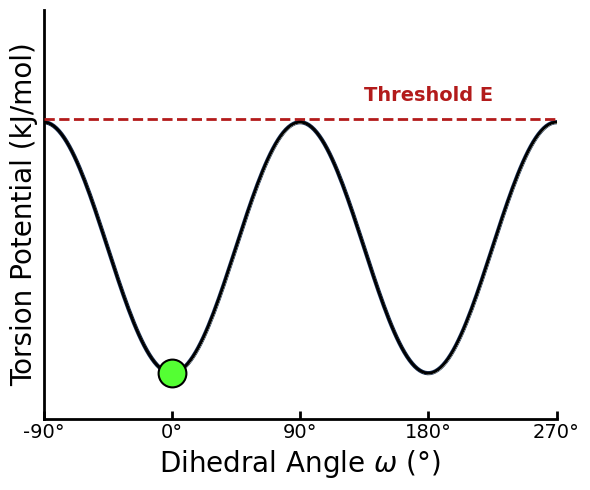

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)

n_steps = 10000
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2

# --- GaMD Specific Parameters ---
threshold_E = 28.0   
k0 = 0.07            
x_pos = -90.0       
history_x = []
history_bias_grid = []

# --- 2. Run Simplified GaMD Simulation ---
for step in range(n_steps):
    alpha = min(1.0, step / 2000.0) 
    dx = 0.5 
    
    v_current = true_fes(x_pos)
    v_plus = true_fes(x_pos + dx)
    v_minus = true_fes(x_pos - dx)
    f_true = -(v_plus - v_minus) / (2 * dx)
    
    if v_current < threshold_E:
        f_boost = -k0 * (threshold_E - v_current) * f_true * alpha
    else:
        f_boost = 0
        
    total_force = f_true + f_boost
    noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    x_pos = x_pos + total_force * mobility * dt + noise
    
    if x_pos > 180.0:
        x_pos -= 360.0
    elif x_pos < -180.0:
        x_pos += 360.0
    
    bias_grid = np.zeros_like(x_grid)
    mask = fes_true_grid < threshold_E
    bias_grid[mask] = 0.5 * k0 * (threshold_E - fes_true_grid[mask])**2 * alpha
        
    history_x.append(x_pos)
    history_bias_grid.append(bias_grid)

# --- 3. Create Animation ---
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
ax.set_facecolor('white')

ax.set_xlim(-180, 180)
ax.set_ylim(-5, 40)
ax.set_xlabel(r'Dihedral Angle $\omega$ (°)', fontsize=20, color='black')
ax.set_ylabel('Torsion Potential (kJ/mol)', fontsize=20, color='black')
ax.tick_params(colors='black', direction='in', length=6, width=2)
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xticklabels(['-90°', '0°', '90°', '180°', '270°'], fontsize=14)
ax.set_yticks([]) 

ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- MODIFIED SECTION ---
# 1. Removed the blue fill_between
# 2. Added the deep blue base line
line_base, = ax.plot(x_grid, fes_true_grid, color='#1a335c', lw=3, zorder=1)

# Threshold line
ax.axhline(threshold_E, color='#b31b1b', linestyle='--', lw=2, zorder=3)
ax.annotate('Threshold E', xy=(90, threshold_E), xytext=(90, threshold_E + 2), 
            color='#b31b1b', fontsize=14, ha='center', fontweight='bold')

# Dynamic elements
fill_bias = ax.fill_between(x_grid, fes_true_grid, fes_true_grid, color='#ffffe0', alpha=1.0, zorder=2)
line_eff_fes, = ax.plot(x_grid, fes_true_grid, color='black', lw=2, zorder=4)
particle, = ax.plot([], [], 'o', markersize=20, markerfacecolor='#54ff33', markeredgecolor='black', markeredgewidth=1.5, zorder=5)

steps_per_frame = 100 

def animate(frame):
    idx = frame * steps_per_frame
    if idx >= len(history_x):
        idx = len(history_x) - 1
        
    current_x = history_x[idx]
    current_bias_grid = history_bias_grid[idx]
    eff_fes = fes_true_grid + current_bias_grid
    
    global fill_bias
    fill_bias.remove()
    # Filling from the deep blue base line to the boosted surface
    fill_bias = ax.fill_between(x_grid, fes_true_grid, eff_fes, color='#ffffe0', alpha=1.0, zorder=2)
    
    line_eff_fes.set_ydata(eff_fes)
    particle_y = np.interp(current_x, x_grid, eff_fes)
    particle.set_data([current_x], [particle_y])
    
    return fill_bias, line_eff_fes, particle

ani = animation.FuncAnimation(fig, animate, frames=n_steps // steps_per_frame, interval=30, blit=False)
plt.tight_layout()

ani.save('gamd.gif', writer='pillow', fps=30, dpi=80, savefig_kwargs={'transparent': False})

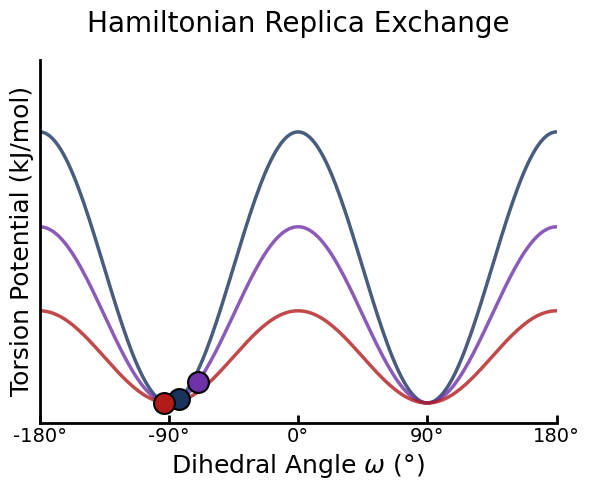

In [157]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)

# Define the 3 Replicas (100%, 65%, 34% barriers)
scaling_factors = np.array([1.0, 0.65, 0.34])
n_replicas = len(scaling_factors)
colors = ['#1a335c', '#6f32a8', '#b31b1b']

# Simulation parameters
n_steps = 6000
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2

exchange_stride = 50  # Try to swap replicas every 50 steps

# Start all replicas in the left well (-90 degrees)
x_pos = np.array([-90.0, -90.0, -90.0])
history_x = []

# --- 2. Run Hamiltonian Replica Exchange Simulation ---
for step in range(n_steps):
    
    # A. Propagate each replica independently on its own scaled landscape
    for i in range(n_replicas):
        dx = 0.5 
        # Force is scaled by the replica's specific scaling factor
        v_plus = true_fes(x_pos[i] + dx) * scaling_factors[i]
        v_minus = true_fes(x_pos[i] - dx) * scaling_factors[i]
        force = -(v_plus - v_minus) / (2 * dx)
        
        noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
        x_pos[i] = x_pos[i] + force * mobility * dt + noise
        
        # Periodic boundary conditions
        if x_pos[i] > 180.0: x_pos[i] -= 360.0
        elif x_pos[i] < -180.0: x_pos[i] += 360.0
            
    # B. Attempt Exchanges
    if step % exchange_stride == 0 and step > 0:
        # Alternate pairs to satisfy detailed balance: swap (0&1) then (1&2)
        pair_idx = (step // exchange_stride) % 2 
        i, j = pair_idx, pair_idx + 1
        
        # Calculate energies of current states
        v_i_xi = true_fes(x_pos[i]) * scaling_factors[i]
        v_j_xj = true_fes(x_pos[j]) * scaling_factors[j]
        
        # Calculate energies if they were to swap coordinates
        v_i_xj = true_fes(x_pos[j]) * scaling_factors[i]
        v_j_xi = true_fes(x_pos[i]) * scaling_factors[j]
        
        # Metropolis criterion for HREX
        delta = (v_i_xj + v_j_xi) - (v_i_xi + v_j_xj)
        
        if delta < 0 or np.random.rand() < np.exp(-delta / kT):
            # SWAP ACCEPTED! Trade coordinates
            x_pos[i], x_pos[j] = x_pos[j], x_pos[i]
            
    # Save the positions of all 3 replicas
    history_x.append(x_pos.copy())

history_x = np.array(history_x)

# --- 3. Create Animation ---
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
ax.set_facecolor('white')

# Axis styling
ax.set_xlim(-180, 180)
ax.set_ylim(-2, 35)
ax.set_xlabel(r'Dihedral Angle $\omega$ (°)', fontsize=18, color='black')
ax.set_ylabel('Torsion Potential (kJ/mol)', fontsize=18, color='black')
ax.set_title('Hamiltonian Replica Exchange', fontsize=20, color='black', pad=20)
ax.tick_params(colors='black', direction='in', length=6, width=2)

ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xticklabels(['-180°', '-90°', '0°', '90°', '180°'], fontsize=14)
ax.set_yticks([]) # Hide Y-ticks

ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Plot the 3 static energy curves
for i in range(n_replicas):
    curve = fes_true_grid * scaling_factors[i]
    ax.plot(x_grid, curve, color=colors[i], lw=2.5, zorder=1, alpha=0.8)

# Initialize the 3 particles (walkers)
particles = []
for i in range(n_replicas):
    p, = ax.plot([], [], 'o', markersize=15, markerfacecolor=colors[i], 
                 markeredgecolor='black', markeredgewidth=1.5, zorder=5)
    particles.append(p)

# --- SPEED CONTROL ---
steps_per_frame = 30 

def animate(frame):
    idx = frame * steps_per_frame
    if idx >= len(history_x):
        idx = len(history_x) - 1
        
    current_positions = history_x[idx]
    
    # Update each particle's position on its respective curve
    for i in range(n_replicas):
        x_val = current_positions[i]
        # Calculate exactly where it sits on the Y-axis for its specific curve
        y_val = true_fes(x_val) * scaling_factors[i]
        particles[i].set_data([x_val], [y_val])
        
    return particles

ani = animation.FuncAnimation(fig, animate, frames=n_steps // steps_per_frame, interval=30, blit=False)
plt.tight_layout()

# Save the GIF
ani.save('replica_exchange.gif', writer='pillow', fps=30, dpi=150, savefig_kwargs={'transparent': False})

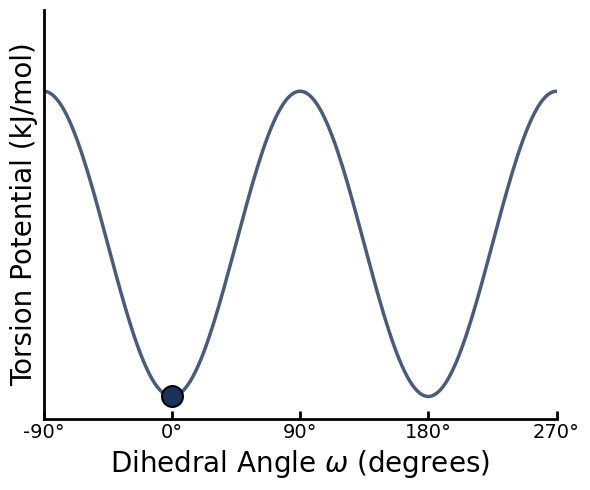

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)

# Simulation parameters
n_steps = 1000
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2

# Start the single walker in the left well (-90 degrees)
x_pos = -90.0
history_x = []

# --- 2. Run Standard Simulation ---
for step in range(n_steps):
    
    # Propagate the single particle
    dx = 0.5 
    v_plus = true_fes(x_pos + dx)
    v_minus = true_fes(x_pos - dx)
    force = -(v_plus - v_minus) / (2 * dx)
    
    noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    x_pos = x_pos + force * mobility * dt + noise
    
    # Periodic boundary conditions
    if x_pos > 180.0: x_pos -= 360.0
    elif x_pos < -180.0: x_pos += 360.0
        
    # Save the position
    history_x.append(x_pos)

history_x = np.array(history_x)

# --- 3. Create Animation ---
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
ax.set_facecolor('white')

# Axis styling
ax.set_xlim(-180, 180)
ax.set_ylim(-2, 35)
ax.set_xlabel(r'Dihedral Angle $\omega$ (degrees)', fontsize=20, color='black')
ax.set_ylabel('Torsion Potential (kJ/mol)', fontsize=20, color='black')
ax.tick_params(colors='black', direction='in', length=6, width=2)

ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xticklabels(['-90°', '0°', '90°', '180°', '270°'], fontsize=14)
ax.set_yticks([]) # Hide Y-ticks

ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Plot the single static energy curve
ax.plot(x_grid, fes_true_grid, color='#1a335c', lw=2.5, zorder=1, alpha=0.8)

# Initialize the single particle
particle, = ax.plot([], [], 'o', markersize=15, markerfacecolor='#1a335c', 
             markeredgecolor='black', markeredgewidth=1.5, zorder=5)

# --- SPEED CONTROL ---
steps_per_frame = 30 

def animate(frame):
    idx = frame * steps_per_frame
    if idx >= len(history_x):
        idx = len(history_x) - 1
        
    x_val = history_x[idx]
    
    # Calculate exactly where it sits on the Y-axis
    y_val = true_fes(x_val)
    particle.set_data([x_val], [y_val])
        
    return particle,

ani = animation.FuncAnimation(fig, animate, frames=n_steps // steps_per_frame, interval=30, blit=False)
plt.tight_layout()

# Save the GIF
ani.save('original_bias.gif', writer='pillow', fps=30, dpi=80, savefig_kwargs={'transparent': False})

Animation created with 50 frames.


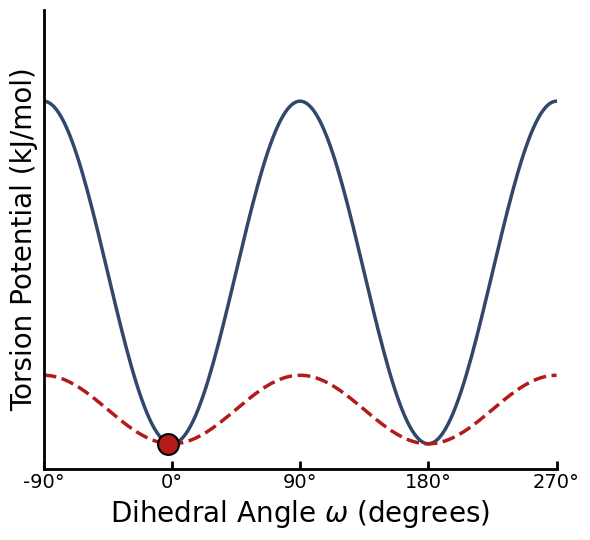

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    """The original unscaled Free Energy Surface."""
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

# Add a tunable bias factor (scales the original barrier down)
# 0.2 means the barrier is 20% of the original height
bias_factor = 0.2 

def biased_fes(omega_deg):
    """The lowered (biased) Free Energy Surface that we simulate on."""
    return bias_factor * true_fes(omega_deg)

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)
fes_biased_grid = biased_fes(x_grid)

# Define distinct colors for the styling swap
color_original = '#1a335c' # Dark Blue
color_biased = '#b31b1b'   # Red

# Simulation parameters
n_steps = 1000
dt = 0.01
kT = 2.49       # Thermal energy
mobility = (180.0 / np.pi)**2 # Arbitrary high mobility for faster angular diffusion

# Start the single walker in the left well (-90 degrees)
x_pos = -90.0
history_x = []

# --- 2. Run Biased Simulation ---
# We simulate dynamics governed ONLY by the biased (lower barrier) potential.
for step in range(n_steps):
    
    # Propagate the single particle on the BIASED landscape (using finite difference for force)
    dx = 0.5 
    v_plus = biased_fes(x_pos + dx)
    v_minus = biased_fes(x_pos - dx)
    
    # Force is now governed strictly by the lower, red dashed biased FES
    force = -(v_plus - v_minus) / (2 * dx)
    
    noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    x_pos = x_pos + force * mobility * dt + noise
    
    # Periodic boundary conditions [-180, 180]
    if x_pos > 180.0: x_pos -= 360.0
    elif x_pos < -180.0: x_pos += 360.0
        
    # Save the position for animation
    history_x.append(x_pos)

history_x = np.array(history_x)

# --- 3. Create Animation ---
fig, ax = plt.subplots(figsize=(6, 5.5), facecolor='white')
ax.set_facecolor('white')

# Axis styling
ax.set_xlim(-180, 180)
ax.set_ylim(-2, 35) # Y-axis scale accommodates the tall original barrier
ax.set_xlabel(r'Dihedral Angle $\omega$ (degrees)', fontsize=20, color='black')
ax.set_ylabel('Torsion Potential (kJ/mol)', fontsize=20, color='black')
ax.tick_params(colors='black', direction='in', length=6, width=2)

ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xticklabels(['-90°', '0°', '90°', '180°', '270°'], fontsize=14)
ax.set_yticks([]) # Hide generic Y-ticks for a cleaner 'Energy Landscape' feel

ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Updated Styling ---

# 1. Original FES: Blue and Solid
line_orig, = ax.plot(x_grid, fes_true_grid, 
                     color=color_original, lw=2.5, linestyle='-', 
                     zorder=1, alpha=0.9, label='Original Potential (Static)')

# 2. Biased FES: Red and Dashed
line_bias, = ax.plot(x_grid, fes_biased_grid, 
                     color=color_biased, lw=2.5, linestyle='--', 
                     zorder=2, alpha=1.0, label='Biased Potential (Simulated)')

# Add legend to clarify styling

# Initialize the single particle tracking on the biased curve (Red spot)
particle, = ax.plot([], [], 'o', markersize=15, 
                     markerfacecolor=color_biased, # Red to match the biased curve
                     markeredgecolor='black', markeredgewidth=1.5, zorder=5)

# --- SPEED CONTROL for GIF ---
steps_per_frame = 20 # Skip steps to speed up animation

def animate(frame):
    idx = frame * steps_per_frame
    if idx >= len(history_x):
        idx = len(history_x) - 1
        
    x_val = history_x[idx]
    
    # Calculate exactly where it sits on the Y-axis (tracking the RED DASHED biased curve)
    y_val = biased_fes(x_val)
    particle.set_data([x_val], [y_val])
        
    return particle,

# Create the animation object
total_frames = n_steps // steps_per_frame
ani = animation.FuncAnimation(fig, animate, frames=total_frames, interval=40, blit=True)

plt.tight_layout()

# Save the resulting GIF
ani.save('biased_potential.gif', writer='pillow', fps=25, dpi=80, savefig_kwargs={'transparent': False})

print(f"Animation created with {total_frames} frames.")

Animation saved as hrex_horizontal_bottom.gif


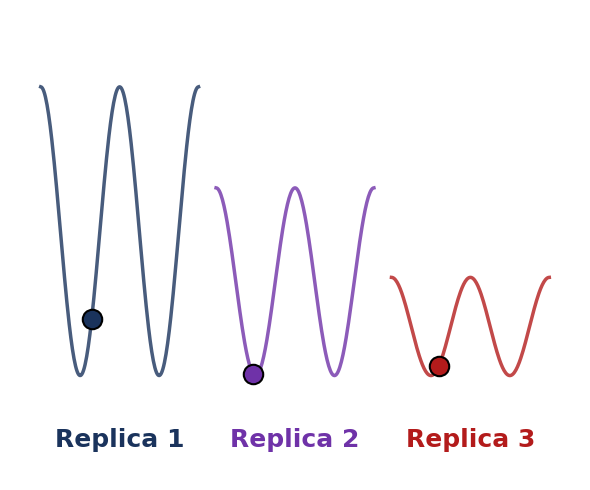

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)
max_fes = np.max(fes_true_grid)

# Define the 3 Replicas
scaling_factors = np.array([1.0, 0.65, 0.34])
n_replicas = len(scaling_factors)

# X-axis offsets to place them side-by-side
offsets = [-400, 0, 400] 
colors = ['#1a335c', '#6f32a8', '#b31b1b']

# Simulation parameters
n_steps = 1000
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2
exchange_stride = 50  

# Tracking the state
x_pos = np.array([-90.0, -90.0, -90.0]) 
walker_ids = np.array([0, 1, 2])        

history_x = []
history_walkers = []
successful_swaps = [] 

# --- 2. Run Hamiltonian Replica Exchange Simulation ---
for step in range(n_steps):
    
    # A. Propagate each replica independently
    for i in range(n_replicas):
        dx = 0.5 
        v_plus = true_fes(x_pos[i] + dx) * scaling_factors[i]
        v_minus = true_fes(x_pos[i] - dx) * scaling_factors[i]
        force = -(v_plus - v_minus) / (2 * dx)
        
        noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
        x_pos[i] = x_pos[i] + force * mobility * dt + noise
        
        if x_pos[i] > 180.0: x_pos[i] -= 360.0
        elif x_pos[i] < -180.0: x_pos[i] += 360.0
            
    # B. Attempt Exchanges
    if step % exchange_stride == 0 and step > 0:
        pair_idx = (step // exchange_stride) % 2 
        i, j = pair_idx, pair_idx + 1
        
        v_i_xi = true_fes(x_pos[i]) * scaling_factors[i]
        v_j_xj = true_fes(x_pos[j]) * scaling_factors[j]
        
        v_i_xj = true_fes(x_pos[j]) * scaling_factors[i]
        v_j_xi = true_fes(x_pos[i]) * scaling_factors[j]
        
        delta = (v_i_xj + v_j_xi) - (v_i_xi + v_j_xj)
        
        if delta < 0 or np.random.rand() < np.exp(-delta / kT):
            # SWAP ACCEPTED! Trade coordinates and walker identities
            x_pos[i], x_pos[j] = x_pos[j], x_pos[i]
            walker_ids[i], walker_ids[j] = walker_ids[j], walker_ids[i]
            successful_swaps.append((step, i, j))
            
    history_x.append(x_pos.copy())
    history_walkers.append(walker_ids.copy())

# --- 3. Create Horizontal Side-by-Side Animation ---
fig, ax = plt.subplots(figsize=(6,5), facecolor='white')
ax.set_facecolor('white')

ax.set_xlim(-650, 650)
ax.set_ylim(-10, 35) 

ax.set_xticks([]) 
ax.set_yticks([]) 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Plot the 3 static energy curves side-by-side (Bottom Aligned)
for i in range(n_replicas):
    curve_y = fes_true_grid * scaling_factors[i]
    curve_x = x_grid + offsets[i] 
    
    ax.plot(curve_x, curve_y, color=colors[i], lw=2.5, zorder=1, alpha=0.8)
    
    labels = ['Replica 1', 'Replica 2', 'Replica 3']
    ax.text(offsets[i], -5, labels[i], ha='center', va='top', fontsize=18, color=colors[i], fontweight='bold')

# Initialize the 3 specific colored particles
particles = []
for i in range(n_replicas):
    p, = ax.plot([], [], 'o', markersize=14, markerfacecolor=colors[i], 
                 markeredgecolor='black', markeredgewidth=1.5, zorder=5)
    particles.append(p)

# Initialize the single double-headed Arrow
swap_arrow = ax.annotate("", xy=(0,0), xytext=(0,0), 
                         arrowprops=dict(arrowstyle="<|-|>", color='#32cd32', lw=3, mutation_scale=20), visible=False, zorder=6)
swap_text = ax.text(0, 0, "EXCHANGED!", color='#32cd32', fontsize=14, fontweight='bold', ha='center', va='bottom', visible=False, zorder=7)


# --- TIMELINE & SPEED CONTROL ---
steps_per_frame = 1 
fps_speed = 30

# Tune this variable to make the pause longer or shorter!
pause_seconds = 2.0 
pause_frames = int(fps_speed * pause_seconds)

# Build a custom frame sequence.
frame_sequence = []
for step in range(0, n_steps, steps_per_frame):
    frame_sequence.append((step, False, None, None))
    
    # Check if a swap happened right here
    swaps_in_window = [s for s in successful_swaps if step - steps_per_frame < s[0] <= step]
    if swaps_in_window:
        _, r1, r2 = swaps_in_window[0]
        for _ in range(pause_frames):
            frame_sequence.append((step, True, r1, r2))

# Animate function now reads from our custom timeline
def animate(frame_idx):
    history_idx, is_paused, r1, r2 = frame_sequence[frame_idx]
        
    current_positions = history_x[history_idx]
    current_walkers = history_walkers[history_idx]
    
    # 1. Update the positions of the particles
    for replica_idx in range(n_replicas):
        walker_idx = current_walkers[replica_idx]
        x_val = current_positions[replica_idx]
        plot_x = x_val + offsets[replica_idx]
        
        # No shift_y applied here
        plot_y = true_fes(x_val) * scaling_factors[replica_idx]
        
        particles[walker_idx].set_data([plot_x], [plot_y])
        
    # 2. Draw the swap arrow if we are in the paused state
    if is_paused:
        # Get coordinates of replica 1
        x_val1 = current_positions[r1]
        plot_x1 = x_val1 + offsets[r1]
        plot_y1 = true_fes(x_val1) * scaling_factors[r1]
        
        # Get coordinates of replica 2
        x_val2 = current_positions[r2]
        plot_x2 = x_val2 + offsets[r2]
        plot_y2 = true_fes(x_val2) * scaling_factors[r2]

        # Connect the two spots perfectly
        swap_arrow.xy = (plot_x2, plot_y2)          # Arrow head 1
        swap_arrow.set_position((plot_x1, plot_y1)) # Arrow head 2 (base)

        # Place the text exactly at the midpoint of the arrow
        mid_x = (plot_x1 + plot_x2) / 2
        mid_y = (plot_y1 + plot_y2) / 2 + 5 
        swap_text.set_position((mid_x, mid_y))

        swap_arrow.set_visible(True)
        swap_text.set_visible(True)
    else:
        swap_arrow.set_visible(False)
        swap_text.set_visible(False)
        
    return particles + [swap_arrow, swap_text]

ani = animation.FuncAnimation(fig, animate, frames=len(frame_sequence), interval=1000//fps_speed, blit=False)
plt.tight_layout()

ani.save('hrex.gif', writer='pillow', fps=fps_speed, dpi=80, savefig_kwargs={'transparent': False})
print("Animation saved as hrex_horizontal_bottom.gif")

Animation saved as expanded_ensemble.gif


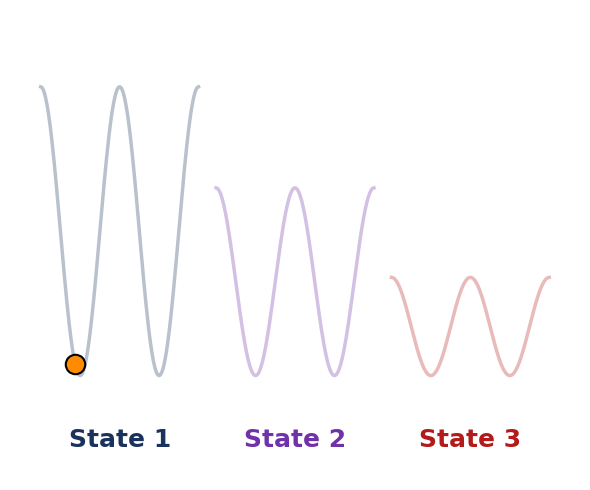

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters ---
def true_fes(omega_deg):
    omega_rad = np.deg2rad(omega_deg)
    K = 13.8229318 # kJ/mol
    return K * (1 + np.cos(2 * omega_rad - 2 * np.pi))

x_grid = np.linspace(-180, 180, 200)
fes_true_grid = true_fes(x_grid)
max_fes = np.max(fes_true_grid)

# Define the 3 Thermodynamic States
scaling_factors = np.array([1.0, 0.65, 0.34])
n_states = len(scaling_factors)

# Layout
offsets = [-400, 0, 400] 
colors = ['#1a335c', '#6f32a8', '#b31b1b']

# Simulation parameters
n_steps = 1000
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2

# Decreased stride to increase exchange frequency
exchange_stride = 15  

# Tracking the single state
x_pos = -90.0 
current_state = 0 # Starts in State 1

history_x = []
history_state = []
successful_transitions = [] 

# --- 2. Run Expanded Ensemble Simulation ---
for step in range(n_steps):
    
    # A. Propagate the single walker in its CURRENT state
    dx = 0.5 
    v_plus = true_fes(x_pos + dx) * scaling_factors[current_state]
    v_minus = true_fes(x_pos - dx) * scaling_factors[current_state]
    force = -(v_plus - v_minus) / (2 * dx)
    
    noise = np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    x_pos = x_pos + force * mobility * dt + noise
    
    # Periodic boundary conditions
    if x_pos > 180.0: x_pos -= 360.0
    elif x_pos < -180.0: x_pos += 360.0
            
    # B. Attempt State Transitions
    if step % exchange_stride == 0 and step > 0:
        
        # Propose a jump to ANY other state purely randomly
        possible_states = [s for s in range(n_states) if s != current_state]
        proposed_state = np.random.choice(possible_states)
        
        # Pure random acceptance (No MCMC energy checks!)
        old_state = current_state
        current_state = proposed_state
        successful_transitions.append((step, old_state, current_state))
            
    history_x.append(x_pos)
    history_state.append(current_state)

# --- 3. Create Horizontal Side-by-Side Animation ---
fig, ax = plt.subplots(figsize=(6,5), facecolor='white')
ax.set_facecolor('white')

ax.set_xlim(-650, 650)
ax.set_ylim(-10, 35) 

ax.set_xticks([]) 
ax.set_yticks([]) 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Plot the 3 static energy curves side-by-side (Bottom Aligned)
for i in range(n_states):
    # Removed shift_y here to keep curves on the bottom baseline
    curve_y = fes_true_grid * scaling_factors[i]
    curve_x = x_grid + offsets[i] 
    
    ax.plot(curve_x, curve_y, color=colors[i], lw=2.5, zorder=1, alpha=0.3)
    
    labels = [f'State 1', f'State 2', f'State 3']
    # Placed labels at a static y=-5 so they align horizontally at the bottom
    ax.text(offsets[i], -5, labels[i], ha='center', va='top', fontsize=18, color=colors[i], fontweight='bold')

# Initialize the SINGLE particle
particle, = ax.plot([], [], 'o', markersize=14, markerfacecolor='#ff8c00', 
                    markeredgecolor='black', markeredgewidth=1.5, zorder=5)

# Initialize the single directional Arrow for state transition
transition_arrow = ax.annotate("", xy=(0,0), xytext=(0,0), 
                               arrowprops=dict(arrowstyle="->", color='#ff8c00', lw=4, mutation_scale=25,
                                               connectionstyle="arc3,rad=0.2"), 
                               visible=False, zorder=6)
transition_text = ax.text(0, 0, "STATE JUMP!", color='#ff8c00', fontsize=14, fontweight='bold', 
                          ha='center', va='bottom', visible=False, zorder=7)

# --- TIMELINE & SPEED CONTROL ---
steps_per_frame = 1 
fps_speed = 30
pause_seconds = 0.5 
pause_frames = int(fps_speed * pause_seconds)

# Build a custom frame sequence
frame_sequence = []
for step in range(0, n_steps, steps_per_frame):
    frame_sequence.append((step, False, None, None))
    
    # Check if a transition happened right here
    trans_in_window = [t for t in successful_transitions if step - steps_per_frame < t[0] <= step]
    if trans_in_window:
        _, old_s, new_s = trans_in_window[0]
        for _ in range(pause_frames):
            frame_sequence.append((step, True, old_s, new_s))

def animate(frame_idx):
    history_idx, is_paused, old_s, new_s = frame_sequence[frame_idx]
        
    curr_x = history_x[history_idx]
    curr_s = history_state[history_idx]
    
    # 1. Update the position of the single particle
    plot_x = curr_x + offsets[curr_s]
    # Removed shift_y to accurately track the bottom-aligned curve
    plot_y = true_fes(curr_x) * scaling_factors[curr_s]
    
    particle.set_data([plot_x], [plot_y])
        
    # 2. Draw the transition arrow if we are in the paused state
    if is_paused:
        plot_x1 = curr_x + offsets[old_s]
        plot_y1 = true_fes(curr_x) * scaling_factors[old_s]
        
        plot_x2 = curr_x + offsets[new_s]
        plot_y2 = true_fes(curr_x) * scaling_factors[new_s]

        transition_arrow.xy = (plot_x2, plot_y2)          
        transition_arrow.set_position((plot_x1, plot_y1)) 

        # Shift the text slightly higher so it doesn't overlap the curved arrow
        mid_x = (plot_x1 + plot_x2) / 2
        mid_y = max(plot_y1, plot_y2) + 10 
        transition_text.set_position((mid_x, mid_y))

        transition_arrow.set_visible(True)
        transition_text.set_visible(True)
    else:
        transition_arrow.set_visible(False)
        transition_text.set_visible(False)
        
    return [particle, transition_arrow, transition_text]

ani = animation.FuncAnimation(fig, animate, frames=len(frame_sequence), interval=1000//fps_speed, blit=False)
plt.tight_layout()

ani.save('expanded_ensemble.gif', writer='pillow', fps=fps_speed, dpi=80, savefig_kwargs={'transparent': False})
print("Animation saved as expanded_ensemble.gif")

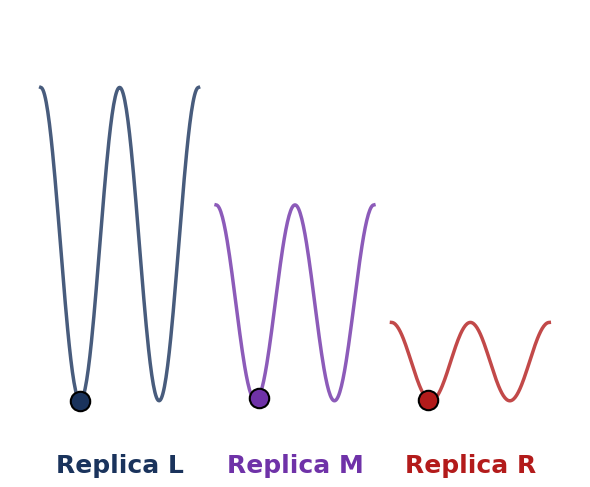

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. System Parameters for REDS ---
def H_L(x):
    """Left Replica: Base Potential (zeta = 1) - High barrier"""
    omega_rad = np.deg2rad(x)
    return 24.0 * (1 + np.cos(2 * omega_rad - 2 * np.pi))

def H_R(x):
    """Right Replica: Perturbed Potential (zeta = 0) - Low barrier"""
    omega_rad = np.deg2rad(x)
    return 6.0 * (1 + np.cos(2 * omega_rad - 2 * np.pi))

def H_M(x, zeta):
    """Middle Replica: Dynamically Scaled Potential"""
    return zeta * H_L(x) + (1.0 - zeta) * H_R(x)

x_grid = np.linspace(-180, 180, 200)

n_replicas = 3
offsets = [-400, 0, 400] 
colors = ['#1a335c', '#6f32a8', '#b31b1b']

# Simulation parameters
n_steps = 1500
dt = 0.01
kT = 2.49       
mobility = (180.0 / np.pi)**2
exchange_stride = 40  

# Track states
x_pos = np.array([-90.0, -90.0, -90.0]) 
walker_ids = np.array([0, 1, 2])        

# --- NEW: Dynamic zeta path (Random Walk bounded between 0 and 1) ---
zeta_history = np.zeros(n_steps)
zeta_history[0] = 0.5  # Start exactly in the middle
step_size = 0.08       # Adjust this value to make the jumps more or less erratic

for i in range(1, n_steps):
    random_shift = np.random.normal(0, step_size)
    new_zeta = zeta_history[i-1] + random_shift
    
    # Reflective boundaries to keep zeta between 0 and 1
    if new_zeta > 1.0: 
        new_zeta = 2.0 - new_zeta
    elif new_zeta < 0.0: 
        new_zeta = -new_zeta
        
    zeta_history[i] = new_zeta

history_x = []
history_walkers = []
successful_swaps = [] 

# --- 2. Run REDS Simulation ---
for step in range(n_steps):
    zeta = zeta_history[step]
    
    dx = 0.5 
    
    # Left Replica 
    f_L = -(H_L(x_pos[0] + dx) - H_L(x_pos[0] - dx)) / (2 * dx)
    x_pos[0] += f_L * mobility * dt + np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    
    # Middle Replica 
    f_M = -(H_M(x_pos[1] + dx, zeta) - H_M(x_pos[1] - dx, zeta)) / (2 * dx)
    x_pos[1] += f_M * mobility * dt + np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    
    # Right Replica 
    f_R = -(H_R(x_pos[2] + dx) - H_R(x_pos[2] - dx)) / (2 * dx)
    x_pos[2] += f_R * mobility * dt + np.random.normal(0, np.sqrt(2 * kT * dt * mobility))
    
    for i in range(3):
        if x_pos[i] > 180.0: x_pos[i] -= 360.0
        elif x_pos[i] < -180.0: x_pos[i] += 360.0
            
    # Attempt Exchanges
    if step % exchange_stride == 0 and step > 0:
        if zeta > 0.8:  
            i, j = 0, 1
            v_i_xi, v_j_xj = H_L(x_pos[i]), H_M(x_pos[j], zeta)
            v_i_xj, v_j_xi = H_L(x_pos[j]), H_M(x_pos[i], zeta)
            
            delta = (v_i_xj + v_j_xi) - (v_i_xi + v_j_xj)
            if delta < 0 or np.random.rand() < np.exp(-delta / kT):
                x_pos[i], x_pos[j] = x_pos[j], x_pos[i]
                walker_ids[i], walker_ids[j] = walker_ids[j], walker_ids[i]
                successful_swaps.append((step, i, j))
                
        elif zeta < 0.2: 
            i, j = 1, 2
            v_i_xi, v_j_xj = H_M(x_pos[i], zeta), H_R(x_pos[j])
            v_i_xj, v_j_xi = H_M(x_pos[j], zeta), H_R(x_pos[i])
            
            delta = (v_i_xj + v_j_xi) - (v_i_xi + v_j_xj)
            if delta < 0 or np.random.rand() < np.exp(-delta / kT):
                x_pos[i], x_pos[j] = x_pos[j], x_pos[i]
                walker_ids[i], walker_ids[j] = walker_ids[j], walker_ids[i]
                successful_swaps.append((step, i, j))
            
    history_x.append(x_pos.copy())
    history_walkers.append(walker_ids.copy())

# --- 3. Create Animation (Bottom-Aligned naturally) ---
fig, ax = plt.subplots(figsize=(6,5), facecolor='white')
ax.set_facecolor('white')
ax.set_xlim(-650, 650)
ax.set_ylim(-10, 60) 
ax.set_xticks([]) 
ax.set_yticks([]) 

# Remove ALL border spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Plot the lines (No vertical shift applied; they naturally bottom-align at y=0)
line_L, = ax.plot(x_grid + offsets[0], H_L(x_grid), color=colors[0], lw=2.5, alpha=0.8)

# M starts in the middle now using offsets[1]
line_M, = ax.plot(x_grid + offsets[1], H_M(x_grid, zeta_history[0]), color=colors[1], lw=2.5, alpha=0.8)

line_R, = ax.plot(x_grid + offsets[2], H_R(x_grid), color=colors[2], lw=2.5, alpha=0.8)

# Labels
ax.text(offsets[0], -8, 'Replica L', ha='center', va='top', fontsize=18, color=colors[0], fontweight='bold')
text_M = ax.text(offsets[1], -8, 'Replica M', ha='center', va='top', fontsize=18, color=colors[1], fontweight='bold')
ax.text(offsets[2], -8, 'Replica R', ha='center', va='top', fontsize=18, color=colors[2], fontweight='bold')

# Initialize the particles
particles = []
for i in range(n_replicas):
    p, = ax.plot([], [], 'o', markersize=14, markerfacecolor=colors[i], markeredgecolor='black', markeredgewidth=1.5, zorder=5)
    particles.append(p)

# Initialize swap arrow
swap_arrow = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="<|-|>", color='#32cd32', lw=3, mutation_scale=20), visible=False, zorder=6)
swap_text = ax.text(0, 0, "EXCHANGED!", color='#32cd32', fontsize=14, fontweight='bold', ha='center', va='bottom', visible=False, zorder=7)

# Timeline Control
steps_per_frame = 2 
fps_speed = 30
pause_seconds = 1.5 
pause_frames = int(fps_speed * pause_seconds)

frame_sequence = []
for step in range(0, n_steps, steps_per_frame):
    frame_sequence.append((step, False, None, None))
    swaps_in_window = [s for s in successful_swaps if step - steps_per_frame < s[0] <= step]
    if swaps_in_window:
        _, r1, r2 = swaps_in_window[0]
        for _ in range(pause_frames):
            frame_sequence.append((step, True, r1, r2))

def animate(frame_idx):
    history_idx, is_paused, r1, r2 = frame_sequence[frame_idx]
        
    current_positions = history_x[history_idx]
    current_walkers = history_walkers[history_idx]
    current_zeta = zeta_history[history_idx]
    
    # Morph the middle potential without shifting it horizontally
    line_M.set_data(x_grid + offsets[1], H_M(x_grid, current_zeta))
    
    # 1. Update the positions of the particles
    for replica_idx in range(n_replicas):
        walker_idx = current_walkers[replica_idx]
        x_val = current_positions[replica_idx]
        
        if replica_idx == 1: 
            plot_x = x_val + offsets[1]
            plot_y = H_M(x_val, current_zeta)
        elif replica_idx == 0: 
            plot_x = x_val + offsets[0]
            plot_y = H_L(x_val)
        else: 
            plot_x = x_val + offsets[2]
            plot_y = H_R(x_val)
        
        particles[walker_idx].set_data([plot_x], [plot_y])
        
    # 2. Draw the swap arrow if paused
    if is_paused:
        def get_coords(idx):
            x = current_positions[idx]
            if idx == 0: 
                return x + offsets[0], H_L(x)
            elif idx == 1: 
                return x + offsets[1], H_M(x, current_zeta)
            else: 
                return x + offsets[2], H_R(x)
            
        px1, py1 = get_coords(r1)
        px2, py2 = get_coords(r2)

        swap_arrow.xy = (px2, py2)
        swap_arrow.set_position((px1, py1))
        swap_text.set_position(((px1 + px2) / 2, (py1 + py2) / 2 + 5))

        swap_arrow.set_visible(True)
        swap_text.set_visible(True)
    else:
        swap_arrow.set_visible(False)
        swap_text.set_visible(False)
        
    return particles + [line_M, text_M, swap_arrow, swap_text]

ani = animation.FuncAnimation(fig, animate, frames=len(frame_sequence), interval=1000//fps_speed, blit=False)
plt.tight_layout()

ani.save('reds.gif', writer='pillow', fps=fps_speed, dpi=80, savefig_kwargs={'transparent': False})

## Staic graph

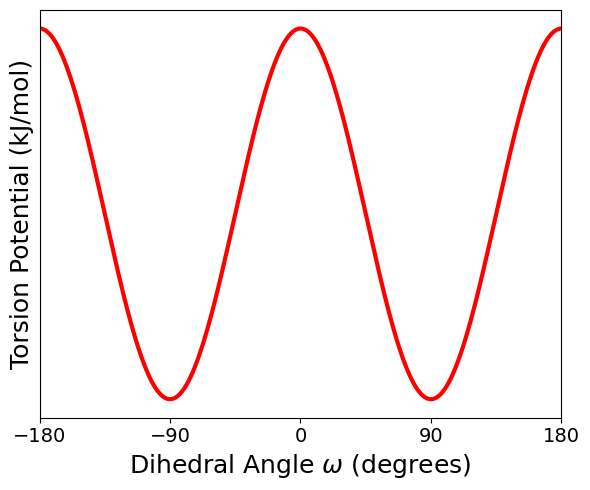

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Constants and Parameters ---
K = 13.8229318  # kJ/mol (Force constant from the STEPs force field)

# Generate omega angles from -180 to 180 degrees
omega_deg = np.linspace(-180, 180, 500)
# Convert to radians for numpy trigonometric functions
omega_rad = np.deg2rad(omega_deg)

# --- 2. Define the Potential Function ---
def dihedral_potential(omega, k_val, num_terms=2):
    """
    Calculates the STEPs force field dihedral potential.
    Multiplied by `num_terms` (2) because both O-C-N-C1 and O-C-N-Calpha 
    contribute to the total 55.2917 kJ/mol barrier.
    """
    # V(w) = K * (1 + cos(2w - 2pi))
    return num_terms * k_val * (1 + np.cos(2 * omega - 2 * np.pi))

# Calculate the true original potential
V_original = dihedral_potential(omega_rad, K)

# --- 3. Define Enhanced Sampling (Lowered Barriers) ---
# We represent sequential lowering of the barrier using scaling factors.
# This mimics the effect of a bias potential (like in metadynamics) 
# or a scaled potential (like in accelerated MD).
scaling_factors = []  # e.g., 80%, 50%, and 20% of the original barrier
colors = ['red']

# --- 4. Plotting ---
plt.figure(figsize=(6, 5), facecolor='none')

# Plot the original physical barrier
plt.plot(omega_deg, V_original, 
         label=f'Original Barrier (100%) $\\approx$ {np.max(V_original):.1f} kJ/mol', 
         linewidth=3, color=
         colors[0])

# Plot the sequentially lowered enhanced sampling barriers
for alpha, color in zip(scaling_factors, colors[1:]):
    V_lowered = V_original * alpha
    plt.plot(omega_deg, V_lowered, 
             label=f'Enhanced Sampling ({int(alpha*100)}% Barrier)', 
             linewidth=2.5, linestyle='--', color=color)

# --- 5. Formatting the Graph ---
plt.xlabel('Dihedral Angle $\omega$ (degrees)', fontsize=18)
plt.ylabel('Torsion Potential (kJ/mol)', fontsize=18)

# Set x-axis ticks to standard angle markers (-180, -90, 0, 90, 180)
plt.xticks(np.arange(-180, 181, 90), fontsize=14)

# ---> HIDE Y-TICKS HERE <---
plt.yticks([])

plt.xlim(-180, 180)

plt.tight_layout()

plt.savefig('cis_trans_energy_barrier.pdf', dpi=300, transparent=True)

# Display the plot
plt.show()

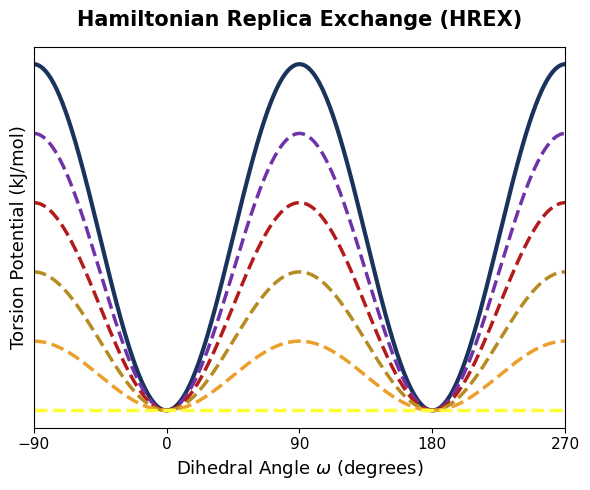

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Constants and Parameters ---
K = 13.8229318  # kJ/mol (Force constant from the STEPs force field)

# Generate omega angles from -180 to 180 degrees
omega_deg = np.linspace(-180, 180, 500)
# Convert to radians for numpy trigonometric functions
omega_rad = np.deg2rad(omega_deg)

# --- 2. Define the Potential Function ---
def dihedral_potential(omega, k_val, num_terms=2):
    """
    Calculates the STEPs force field dihedral potential.
    Multiplied by `num_terms` (2) because both O-C-N-C1 and O-C-N-Calpha 
    contribute to the total 55.2917 kJ/mol barrier.
    """
    # V(w) = K * (1 + cos(2w - 2pi))
    return num_terms * k_val * (1 + np.cos(2 * omega - 2 * np.pi))

# Calculate the true original potential based on original unshifted angles
V_original = dihedral_potential(omega_rad, K)

# Shift the x-axis values by +90 degrees for plotting
omega_deg_shifted = omega_deg + 90

# --- 3. Define Enhanced Sampling (Lowered Barriers) ---
scaling_factors = [0.8, 0.6, 0.4, 0.2, 0.0]  # e.g., 80%, 50%, and 20% of the original barrier
colors = ['#1a335c', '#6f32a8', '#b31b1b', '#b58b22', '#ed9f2b', '#fdfd33'] # Red, Orange, Green

# --- 4. Plotting ---
plt.figure(figsize=(6, 5), facecolor='none')

# Plot the original physical barrier with shifted x-axis
plt.plot(omega_deg_shifted, V_original, 
         label=f'Original Barrier (100%) $\\approx$ {np.max(V_original):.1f} kJ/mol', 
         linewidth=3, color=colors[0])

# Plot the sequentially lowered enhanced sampling barriers with shifted x-axis
for alpha, color in zip(scaling_factors, colors[1:]):
    V_lowered = V_original * alpha
    plt.plot(omega_deg_shifted, V_lowered, 
             label=f'Enhanced Sampling ({int(alpha*100)}% Barrier)', 
             linewidth=2.5, linestyle='--', color=color)

# --- 5. Formatting the Graph ---
plt.title('Hamiltonian Replica Exchange (HREX)', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Dihedral Angle $\omega$ (degrees)', fontsize=13)
plt.ylabel('Torsion Potential (kJ/mol)', fontsize=13)

# Update x-axis ticks to match the new shifted range (-90 to 270)
plt.xticks(np.arange(-90, 271, 90), fontsize=11)

# ---> HIDE Y-TICKS HERE <---
plt.yticks([])

# Update x-limits to the shifted range
plt.xlim(-90, 270)

plt.tight_layout()

plt.savefig('HREX.pdf', dpi=300, transparent=True)

# Display the plot
plt.show()

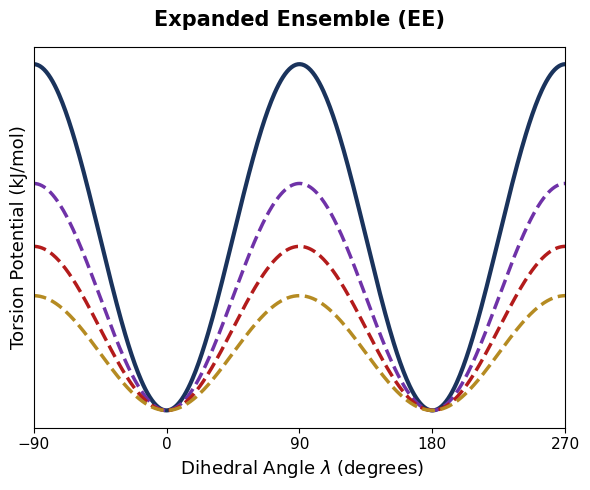

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Constants and Parameters ---
K = 13.8229318  # kJ/mol (Force constant from the STEPs force field)

# Generate omega angles from -180 to 180 degrees
omega_deg = np.linspace(-180, 180, 500)
# Convert to radians for numpy trigonometric functions
omega_rad = np.deg2rad(omega_deg)

# --- 2. Define the Potential Function ---
def dihedral_potential(omega, k_val, num_terms=2):
    """
    Calculates the STEPs force field dihedral potential.
    Multiplied by `num_terms` (2) because both O-C-N-C1 and O-C-N-Calpha 
    contribute to the total 55.2917 kJ/mol barrier.
    """
    # V(w) = K * (1 + cos(2w - 2pi))
    return num_terms * k_val * (1 + np.cos(2 * omega - 2 * np.pi))

# Calculate the true original potential based on original unshifted angles
V_original = dihedral_potential(omega_rad, K)

# Shift the x-axis values by +90 degrees for plotting
omega_deg_shifted = omega_deg + 90

# --- 3. Define Enhanced Sampling (Lowered Barriers) ---
lambda_values = [0.34457, 0.52623, 0.66864]
scaling_factors = 1 - np.array(lambda_values)  
colors = ['#1a335c', '#6f32a8', '#b31b1b', '#b58b22', '#ed9f2b', '#fdfd33']

# --- 4. Plotting ---
plt.figure(figsize=(6, 5), facecolor='none')

# Plot the original physical barrier with shifted x-axis
plt.plot(omega_deg_shifted, V_original, 
         label=f'Original Barrier (100%) $\\approx$ {np.max(V_original):.1f} kJ/mol', 
         linewidth=3, color=colors[0])

# Plot the sequentially lowered enhanced sampling barriers with shifted x-axis
for alpha, color in zip(scaling_factors, colors[1:]):
    V_lowered = V_original * alpha
    plt.plot(omega_deg_shifted, V_lowered, 
             label=f'Enhanced Sampling ({int(alpha*100)}% Barrier)', 
             linewidth=2.5, linestyle='--', color=color)

# --- 5. Formatting the Graph ---
plt.title('Expanded Ensemble (EE)', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel(' Dihedral Angle $\lambda$ (degrees)', fontsize=13)
plt.ylabel('Torsion Potential (kJ/mol)', fontsize=13)

# Update x-axis ticks to match the new shifted range (-90 to 270)
plt.xticks(np.arange(-90, 271, 90), fontsize=11)

# ---> HIDE Y-TICKS HERE <---
plt.yticks([])

# Update x-limits to the shifted range
plt.xlim(-90, 270)

plt.tight_layout()

plt.savefig('EE.pdf', dpi=300, transparent=True)

# Display the plot
plt.show()

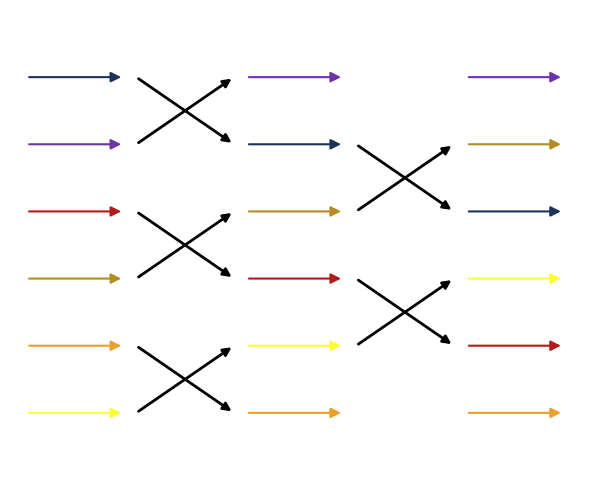

In [129]:
import matplotlib.pyplot as plt

def draw_permutation_network():
    # 1. Setup figure and axis
    # Added facecolor='none' to the figure creation
    fig, ax = plt.subplots(figsize=(6, 5), facecolor='none')
    
    # Set both the axis and figure patch backgrounds to 'none' (transparent)
    ax.set_facecolor('none')  
    fig.patch.set_facecolor('none')

    # 2. Define initial variables
    # Colors for the lines (from top to bottom)
    colors = ['#1a335c', '#6f32a8', '#b31b1b', '#b58b22', '#ed9f2b', '#fdfd33']
    
    # Y-coordinates for the 6 horizontal lines (top to bottom)
    y_coords = [6, 5, 4, 3, 2, 1]
    
    # Layout dimensions
    x = 0
    h_len = 1.2  # Length of horizontal arrows
    s_len = 1.2  # Width of the crossing area
    gap = 0.15   # Gap between the arrows and the crosses

    # 3. Helper functions for drawing
    def draw_h_arrow(x_start, y, color):
        """Draws a colored horizontal arrow."""
        ax.annotate("", xy=(x_start + h_len, y), xytext=(x_start, y),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.5, mutation_scale=15))

    def draw_cross(x_start, y_top, y_bot):
        """Draws the thin black crossing arrows representing a swap."""
        # Arrow going down
        ax.annotate("", xy=(x_start + s_len, y_bot), xytext=(x_start, y_top),
                    arrowprops=dict(arrowstyle="-|>", color='black', lw=2.0, mutation_scale=12))
        # Arrow going up
        ax.annotate("", xy=(x_start + s_len, y_top), xytext=(x_start, y_bot),
                    arrowprops=dict(arrowstyle="-|>", color='black', lw=2.0, mutation_scale=12))

    # --- Stage 1: Initial Horizontal Lines ---
    for i in range(6):
        draw_h_arrow(x, y_coords[i], colors[i])
    x += h_len + gap
    
    # --- Stage 2: First Set of Swaps ---
    # Swapping (Line 1 & 2), (Line 3 & 4), (Line 5 & 6) -> 0-indexed
    swaps_1 = [(0, 1), (2, 3), (4, 5)]
    next_colors = colors.copy()
    
    for top_idx, bot_idx in swaps_1:
        draw_cross(x, y_coords[top_idx], y_coords[bot_idx])
        # Swap the colors in our state tracker
        next_colors[top_idx] = colors[bot_idx]
        next_colors[bot_idx] = colors[top_idx]
        
    colors = next_colors
    x += s_len + gap
    
    # --- Stage 3: Middle Horizontal Lines ---
    for i in range(6):
        draw_h_arrow(x, y_coords[i], colors[i])
    x += h_len + gap
    
    # --- Stage 4: Second Set of Swaps ---
    # Swapping (Line 2 & 3), (Line 4 & 5) -> 0-indexed
    swaps_2 = [(1, 2), (3, 4)]
    next_colors = colors.copy()
    
    for top_idx, bot_idx in swaps_2:
        draw_cross(x, y_coords[top_idx], y_coords[bot_idx])
        # Swap the colors in our state tracker
        next_colors[top_idx] = colors[bot_idx]
        next_colors[bot_idx] = colors[top_idx]
        
    colors = next_colors
    x += s_len + gap
    
    # --- Stage 5: Final Horizontal Lines ---
    for i in range(6):
        draw_h_arrow(x, y_coords[i], colors[i])
        
    # 4. Final plot formatting
    ax.set_xlim(-0.2, x + h_len + 0.2)
    ax.set_ylim(0, 7)
    ax.axis('off')  # Hide the axes boundaries and ticks
    
    plt.tight_layout()

    # ---> SAVE BEFORE SHOWING <---
    plt.savefig('HREX_state.pdf', dpi=300, transparent=True)
    
    # Display the plot
    plt.show()

# Run the function
if __name__ == "__main__":
    draw_permutation_network()

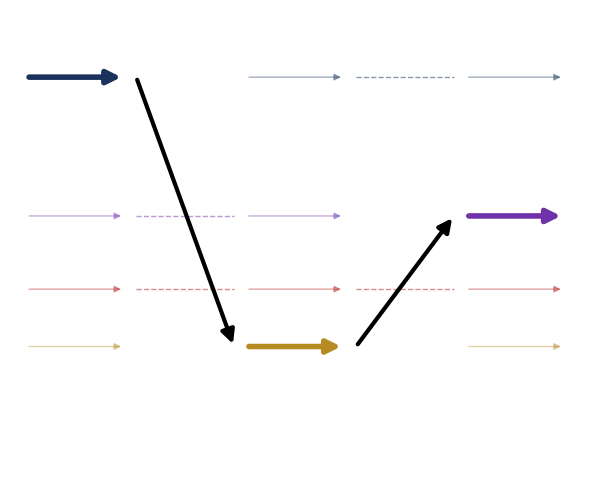

In [139]:
import matplotlib.pyplot as plt
import numpy as np

def draw_permutation_network():
    # 1. Setup figure and axis
    fig, ax = plt.subplots(figsize=(6, 5), facecolor='none')
    ax.set_facecolor('none')  
    fig.patch.set_facecolor('none')

    # 2. Define exactly 4 states
    lambda_values = [0.0, 0.34457, 0.52623, 0.66864]
    scaling_factors = 1.0 - np.array(lambda_values)
    y_coords = scaling_factors * 6.0 
    
    colors = ['#1a335c', '#6f32a8', '#b31b1b', '#b58b22']
    
    # Layout dimensions
    x = 0
    h_len = 1.2  
    s_len = 1.2  
    gap = 0.15   
    
    # Walker starts at state 0
    walker_state = 0 

    # 3. Helper functions for drawing
    def draw_h_arrow(x_start, y, color, is_active=False):
        """Draws a horizontal arrow. Bold if it is the walker's active path."""
        # Make active path thick and bold, inactive path thin and slightly faded
        lw = 4.0 if is_active else 1.0
        ms = 20 if is_active else 10
        alpha = 1.0 if is_active else 0.4
        
        ax.annotate("", xy=(x_start + h_len, y), xytext=(x_start, y),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, 
                                    mutation_scale=ms, alpha=alpha))

    def draw_jump(x_start, from_idx, to_idx):
        """Draws the bold black jump arrow for the walker."""
        y_from = y_coords[from_idx]
        y_to = y_coords[to_idx]
        
        ax.annotate("", xy=(x_start + s_len, y_to), xytext=(x_start, y_from),
                    arrowprops=dict(arrowstyle="-|>", color='black', lw=3.0, mutation_scale=20))

    def draw_idle_gap(x_start, state_idx):
        """Draws a faint dotted line across the gap for states that are not jumping."""
        y = y_coords[state_idx]
        ax.plot([x_start, x_start + s_len], [y, y], color=colors[state_idx], 
                lw=1.0, ls='--', alpha=0.5)

    # --- Stage 1: Initial Horizontal Lines ---
    for i in range(4):
        draw_h_arrow(x, y_coords[i], colors[i], is_active=(i == walker_state))
    x += h_len + gap
    
    # --- Stage 2: First Jump (0 -> 3) ---
    jump_from = walker_state
    jump_to = 3
    
    draw_jump(x, jump_from, jump_to)
    for i in range(4):
        if i != jump_from and i != jump_to:
            draw_idle_gap(x, i)
            
    walker_state = jump_to # Update walker position
    x += s_len + gap
    
    # --- Stage 3: Middle Horizontal Lines ---
    for i in range(4):
        draw_h_arrow(x, y_coords[i], colors[i], is_active=(i == walker_state))
    x += h_len + gap
    
    # --- Stage 4: Second Jump (3 -> 1) ---
    jump_from = walker_state
    jump_to = 1
    
    draw_jump(x, jump_from, jump_to)
    for i in range(4):
        if i != jump_from and i != jump_to:
            draw_idle_gap(x, i)
            
    walker_state = jump_to # Update walker position
    x += s_len + gap
    
    # --- Stage 5: Final Horizontal Lines ---
    for i in range(4):
        draw_h_arrow(x, y_coords[i], colors[i], is_active=(i == walker_state))
        
    # 4. Final plot formatting
    ax.set_xlim(-0.2, x + h_len + 0.2)
    ax.set_ylim(0, 7)
    ax.axis('off')  
    
    plt.tight_layout()

    # SAVE BEFORE SHOWING
    plt.savefig('EE_state.pdf', dpi=300, transparent=True)
    
    plt.show()

# Run the function
if __name__ == "__main__":
    draw_permutation_network()

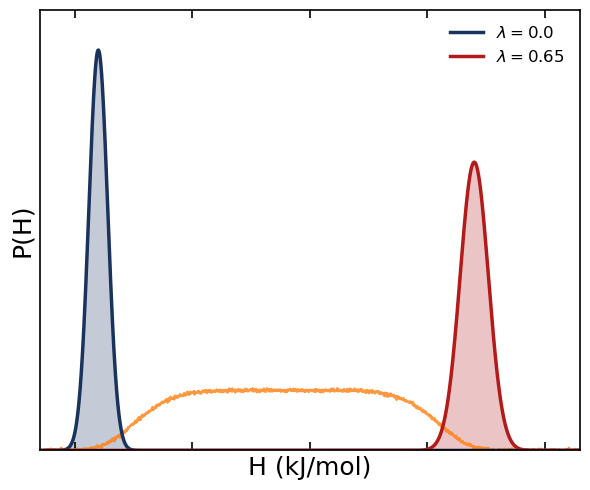

In [148]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Set up the X-axis (Energy H in kJ/mol) ---
x = np.linspace(-175000, -125000, 2000)

# --- 2. Define Distribution Functions ---
def gaussian(x, mu, sigma, amp):
    """Standard Gaussian for the sharp peaks"""
    return amp * np.exp(-0.5 * ((x - mu) / sigma)**2)

def super_gaussian(x, mu, sigma, power, amp):
    """Flat-topped Gaussian for the broad background distributions"""
    base = amp * np.exp(-0.5 * (np.abs(x - mu) / sigma)**power)
    # Add a tiny amount of noise to mimic raw simulation histogram data
    noise = np.random.normal(0, amp * 0.015, len(x))
    return np.clip(base + noise, 0, None)  # Prevent negative values

# --- 3. Generate Data ---
# Two Sharp Peaks for the 2 Hamiltonians
peak1 = gaussian(x, mu=-168000, sigma=800,  amp=1.0)   # State 1: Lambda = 0.0
peak2 = gaussian(x, mu=-136000, sigma=1200, amp=0.72)  # State 2: Lambda = 0.65

# Broad/Flat Distribution representing the biased/expanded sampling
flat_bg = super_gaussian(x, mu=-152000, sigma=12000, power=6, amp=0.15)

# --- 4. Plotting ---
fig, ax = plt.subplots(figsize=(6, 5), facecolor='none')

# Plot flat background distribution first so it stays in the back
ax.plot(x, flat_bg, color='#ff7f0e', linewidth=1.5, alpha=0.8)

# Colors matching your extreme states (Blue and Red)
colors = ['#1a335c', '#b31b1b']

# Plot the 2 sharp peaks
ax.plot(x, peak1, color=colors[0], linewidth=2.5, label=r'$\lambda = 0.0$')
ax.plot(x, peak2, color=colors[1], linewidth=2.5, label=r'$\lambda = 0.65$')

# Light shading under the peaks for a polished look
ax.fill_between(x, 0, peak1, color=colors[0], alpha=0.25)
ax.fill_between(x, 0, peak2, color=colors[1], alpha=0.25)

# --- 5. Formatting to Match the Image ---
ax.set_xlim(-173000, -127000)
ax.set_ylim(0, 1.1)

# Labels
ax.set_xlabel('H (kJ/mol)', fontsize=18)
ax.set_ylabel('P(H)', fontsize=18)

# Ticks configuration
ax.set_yticks([]) # Remove Y-axis ticks/numbers

# Add inward-pointing ticks on top and bottom, and HIDE the bottom labels
ax.tick_params(axis='x', direction='in', length=6, width=1.2, top=True, bottom=True, labelbottom=False)

# Thicken the border box (spines)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# Add a clean legend
ax.legend(loc='upper right', frameon=False, fontsize=12)

plt.tight_layout()

# SAVE FIRST
plt.savefig('REDS.pdf', dpi=300, transparent=True)

# Display the plot
plt.show()

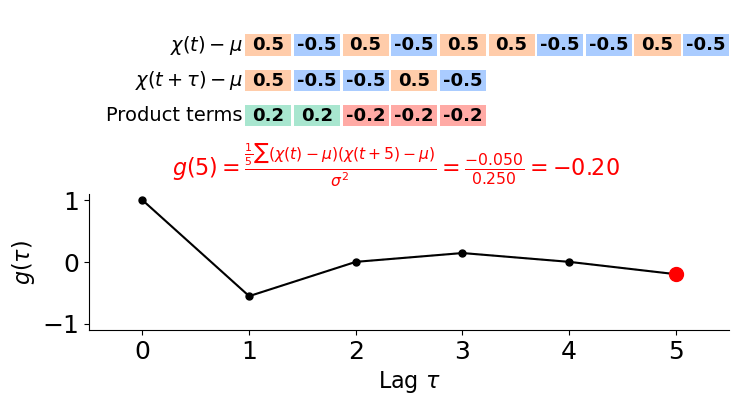

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches

# --- 1. Data Setup ---
traj = np.array([1, 0, 1, 0, 1, 1, 0, 0, 1, 0])
N = len(traj)
max_tau = 5
mu = np.mean(traj)
variance = np.mean((traj - mu)**2) 
x_mean = traj - mu

g_tau_vals = []
for t in range(max_tau + 1):
    if N - t > 0:
        cov_tau = np.mean(x_mean[:N-t] * x_mean[t:])
        g_tau_vals.append(cov_tau / variance)
    else:
        g_tau_vals.append(0)

# --- 2. Layout ---
fig = plt.figure(figsize=(8, 4), facecolor='white')
gs = fig.add_gridspec(2, 1, height_ratios=[1.3, 1], hspace=0.05)
ax_grid = fig.add_subplot(gs[0])
ax_plot = fig.add_subplot(gs[1])

x_spacing = 1.9 # Increased spacing for better clarity

def draw_block(ax, x_idx, y, val, is_product=False):
    x_pos = x_idx * x_spacing 
    # Color logic remains the same
    color = ('#ffaaa5' if val < 0 else '#a8e6cf') if is_product else ('#aaccff' if val < 0 else '#ffccaa')
    
    # ADJUSTED: Height and Width for better "block" look
    # Rectangle( (x_bottom_left, y_bottom_left), width, height )
    rect = patches.Rectangle((x_pos - 0.9, y - 0.3), 1.8, 0.6, facecolor=color)
    ax.add_patch(rect)
    
    # ADJUSTED: Removed the '+' from f-string formatting
    # Changed fontsize to 10 for better visibility inside the block
    ax.text(x_pos, y, f"{val:.1f}", ha='center', va='center', fontsize=13, fontweight='bold')

tau_sequence = np.arange(max_tau + 1)

def animate(frame_idx):
    tau = tau_sequence[frame_idx]
    ax_grid.clear()
    
    ax_grid.set_ylim(-1.5, 3.5)
    ax_grid.set_xlim(-7, 18)
    ax_grid.axis('off')
    
    # Labels
    ax_grid.text(-1, 2.5, "$\\chi(t) - \\mu$", ha='right', va='center', fontsize=14)
    ax_grid.text(-1, 1.5, "$\\chi(t + \\tau) - \\mu$", ha='right', va='center', fontsize=14)
    ax_grid.text(-1, 0.5, "Product terms", ha='right', va='center', fontsize=14)
    
    # Draw Blocks
    for i in range(N):
        draw_block(ax_grid, i, 2.5, x_mean[i])
    
    for i in range(N - tau):
        draw_block(ax_grid, i, 1.5, x_mean[i + tau])
        
    sum_prod = 0
    num_terms = N - tau
    for i in range(num_terms):
        prod = x_mean[i] * x_mean[i + tau]
        sum_prod += prod
        draw_block(ax_grid, i, 0.5, prod, is_product=True)

    numerator = sum_prod / num_terms if num_terms > 0 else 0
    g_val = numerator / variance

    # Formula
    math_str = (f"$g({tau}) = \\frac{{\\frac{{1}}{{{num_terms}}}\\sum (\\chi(t)-\\mu)(\\chi(t+{tau})-\\mu)}}"
                f"{{\\sigma^2}} = \\frac{{{numerator:.3f}}}{{{variance:.3f}}} = {g_val:.2f}$")
    
    ax_grid.text(5, -1.2, math_str, color='red', fontsize=16, ha='center', fontweight='bold', 
                 bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'))

    # --- Bottom Plot ---
    ax_plot.clear()
    ax_plot.set_xlim(-0.5, max_tau + 0.5)
    ax_plot.set_ylim(-1.1, 1.1)
    ax_plot.set_xticks(range(max_tau + 1))
    ax_plot.set_ylabel("$g(\\tau)$", fontsize=16)
    ax_plot.set_xlabel("Lag $\\tau$", fontsize=16)
    
    ax_plot.plot(range(max_tau + 1), g_tau_vals, 'gray', ls=':', alpha=0.3)
    ax_plot.plot(range(tau + 1), g_tau_vals[:tau+1], 'ko-', markersize=5, lw=1.5)
    ax_plot.plot(tau, g_val, 'ro', markersize=10)
    
    ax_plot.spines[['top', 'right']].set_visible(False)

plt.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.15)
ani = animation.FuncAnimation(fig, animate, frames=len(tau_sequence), interval=2000)
ani.save('autocorrelation.gif', writer='pillow', fps=0.5, dpi=120)

plt.show()

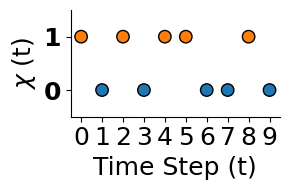

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Data Setup ---
traj = np.array([1, 0, 1, 0, 1, 1, 0, 0, 1, 0])
time = np.arange(len(traj))

# --- 2. Plotting ---
# Increased figure height slightly to 2.5 to prevent label clipping with large fonts
plt.figure(figsize=(3, 2), facecolor='white')

# 0 (Cis) will be Blue, 1 (Trans) will be Orange
colors = ['#1f77b4' if x == 0 else '#ff7f0e' for x in traj]

plt.scatter(time, traj, c=colors, s=80, edgecolor='black', zorder=3)

# --- 3. Formatting ---
plt.yticks([0, 1], ['0', '1'], fontsize=18, fontweight='bold')
plt.xticks(time, fontsize=18)
plt.xlabel("Time Step (t)", fontsize=18)
plt.ylabel("$\chi$ (t)", fontsize=18)

# Clean up the look
plt.gca().spines[['top', 'right']].set_visible(False)
plt.ylim(-0.5, 1.5) 
plt.xlim(-0.5, 9.5) # Ensure first and last points aren't cut off

plt.tight_layout()

# --- 4. Save with Transparency ---
# 'bbox_inches=tight' is crucial to ensure large fonts aren't cut off in the PDF
plt.savefig('example_traj_auto.pdf', transparent=True, bbox_inches='tight')

plt.show()

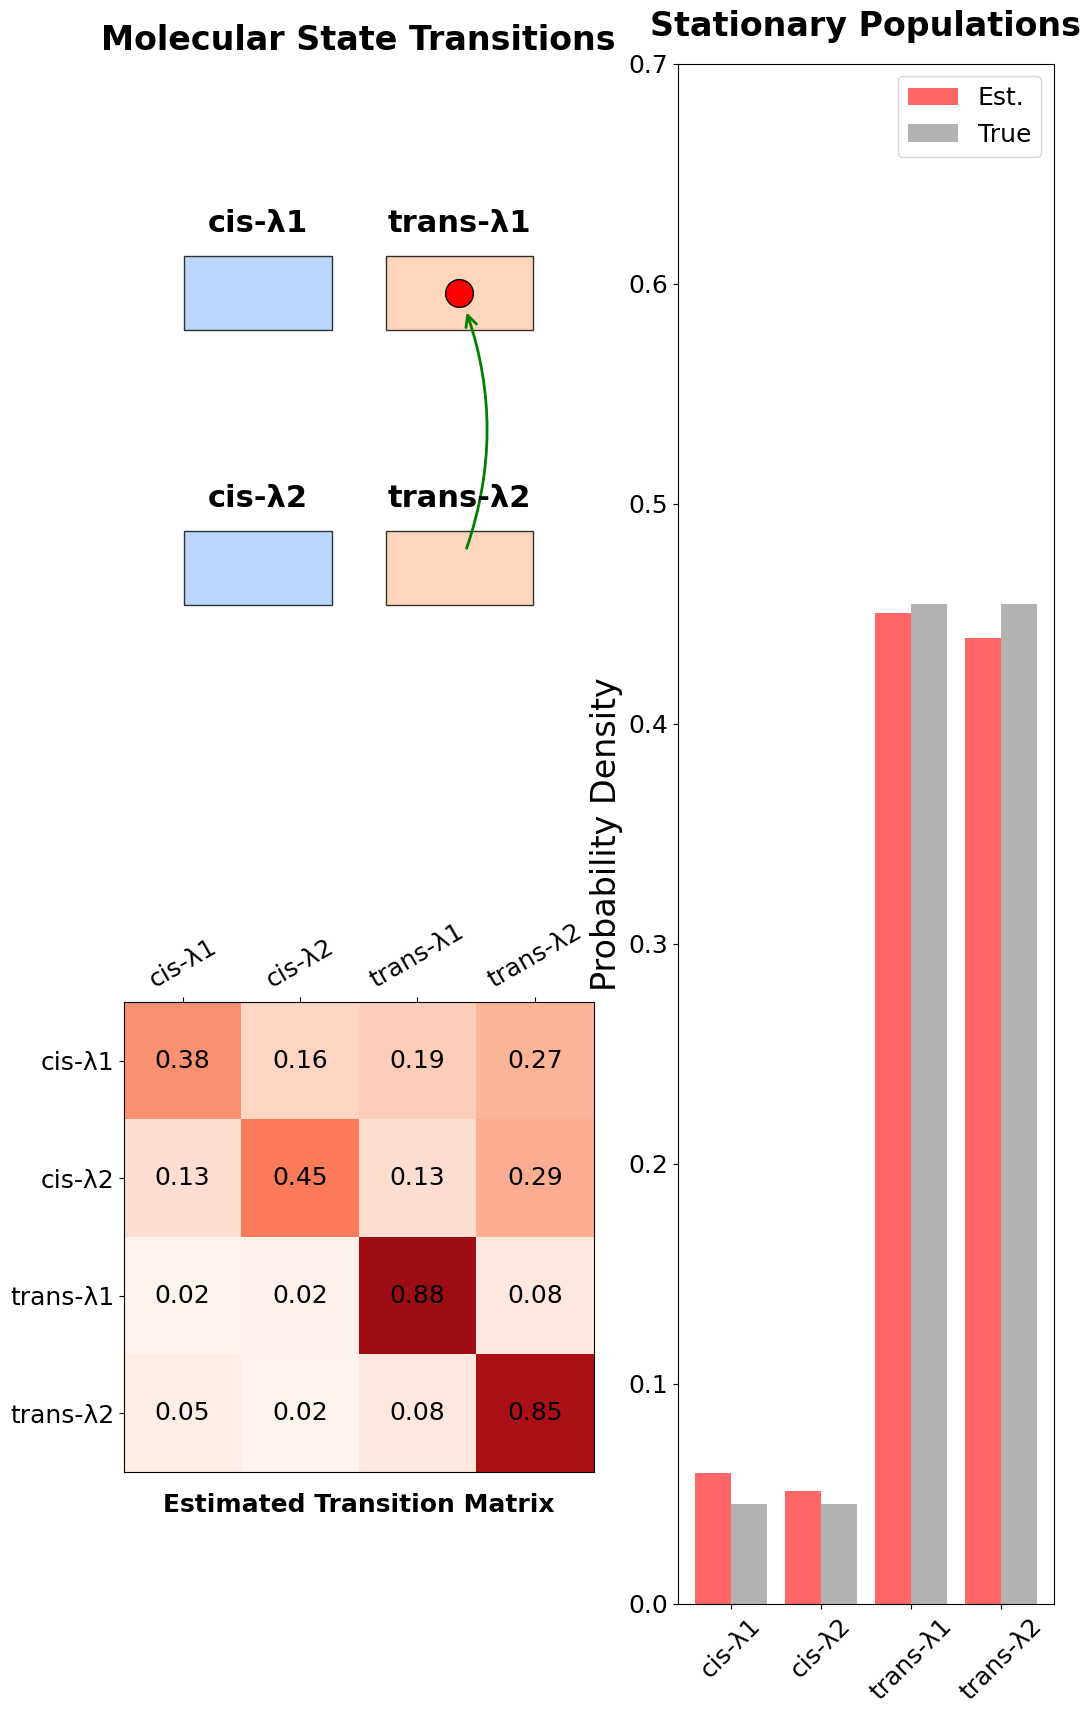

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches

# --- 1. Simulation Parameters & Setup ---
state_names = ["cis-λ1", "cis-λ2", "trans-λ1", "trans-λ2"]
state_coords = {0: (1.2, 1.8), 1: (1.2, 1.2), 2: (1.8, 1.8), 3: (1.8, 1.2)}

T_true = np.array([
    [0.40, 0.10, 0.25, 0.25], 
    [0.10, 0.40, 0.25, 0.25], 
    [0.02, 0.03, 0.85, 0.10], 
    [0.03, 0.02, 0.10, 0.85]  
])

vals_true, vecs_true = np.linalg.eig(T_true.T)
idx_true = np.argmin(np.abs(vals_true - 1.0))
true_stat_pop = np.real(vecs_true[:, idx_true])
true_stat_pop /= true_stat_pop.sum()

counts = np.zeros((4, 4))
T_est = np.eye(4)
total_frames = 600
current_state = 0

# --- 2. Figure Setup ---
plt.rcParams.update({'font.size': 18}) 

fig = plt.figure(figsize=(12, 20), facecolor='white')

gs = fig.add_gridspec(2, 2, hspace=0.1, wspace=0.2, height_ratios=[1, 1], width_ratios=[1, 0.8])

ax_sim = fig.add_subplot(gs[0, 0]) 
ax_mat_est = fig.add_subplot(gs[1, 0]) 
ax_pop = fig.add_subplot(gs[:, 1]) 

# --- Simulation Styling ---
ax_sim.set_xlim(0.8, 2.2)
ax_sim.set_ylim(0.7, 2.3)
ax_sim.axis('off')
ax_sim.set_title("Molecular State Transitions", fontsize=24, fontweight='bold', pad=10)

for s, (x, y) in state_coords.items():
    color = '#aaccff' if "cis" in state_names[s] else '#ffccaa'
    rect = patches.Rectangle((x-0.22, y-0.08), 0.44, 0.16, facecolor=color, edgecolor='black', alpha=0.8)
    ax_sim.add_patch(rect)
    ax_sim.text(x, y+0.12, state_names[s], ha='center', va='bottom', fontsize=22, fontweight='bold')

spot, = ax_sim.plot([], [], 'ro', markersize=20, markeredgecolor='black', zorder=10)
active_elements = []

# --- Matrix Styling ---
def setup_matrix_ax(ax, title, data):
    img = ax.imshow(data, cmap='Reds', vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_yticklabels(state_names, fontsize=18)
    
    # Keep X-axis tick labels at the top
    ax.xaxis.tick_top()
    ax.set_xticklabels(state_names, rotation=30, fontsize=18)
    
    # Place the "title" at the bottom using the xlabel
    ax.xaxis.set_label_position('bottom') 
    ax.set_xlabel(title, fontweight='bold', fontsize=18, labelpad=15)
    
    text_list = [ax.text(j, i, f'{data[i,j]:.2f}', ha="center", va="center", fontsize=18) for i in range(4) for j in range(4)]
    return img, text_list

im_est, texts_est = setup_matrix_ax(ax_mat_est, "Estimated Transition Matrix", T_est)

# --- Population Styling ---
ax_pop.set_ylim(0, 0.7) 
ax_pop.set_xticks(np.arange(4))
ax_pop.set_xticklabels(state_names, rotation=45, fontsize=18)
ax_pop.set_title("Stationary Populations", fontweight='bold', fontsize=24, pad=20)
pop_bars_est = ax_pop.bar(np.arange(4)-0.2, np.ones(4)/4, width=0.4, label='Est.', color='red', alpha=0.6)
pop_bars_true = ax_pop.bar(np.arange(4)+0.2, true_stat_pop, width=0.4, label='True', color='black', alpha=0.3)
ax_pop.legend(fontsize=18, loc='upper right')
ax_pop.set_ylabel("Probability Density", fontsize=24)

# --- 3. Animation Logic ---
def update(frame):
    global current_state, T_est, counts, active_elements
    for element in active_elements:
        element.remove()
    active_elements = []

    start_pos = state_coords[current_state]
    next_state = np.random.choice([0,1,2,3], p=T_true[current_state])
    counts[current_state, next_state] += 1
    end_pos = state_coords[next_state]

    if current_state == next_state:
        txt = ax_sim.text(start_pos[0], start_pos[1]-0.25, "STAY", 
                          color='darkgreen', fontweight='bold', ha='center', fontsize=18)
        active_elements.append(txt)
    else:
        arr = patches.FancyArrowPatch(start_pos, end_pos, connectionstyle="arc3,rad=0.2", 
                                      arrowstyle='->', mutation_scale=20, color='green', 
                                      lw=2, shrinkA=15, shrinkB=15)
        ax_sim.add_patch(arr)
        active_elements.append(arr)

    current_state = next_state
    spot.set_data([end_pos[0]], [end_pos[1]])
    
    # Calculate estimation
    T_est = (counts + 0.1) / (counts + 0.1).sum(axis=1, keepdims=True)
    vals, vecs = np.linalg.eig(T_est.T)
    idx = np.argmin(np.abs(vals - 1.0))
    stat_pop = np.real(vecs[:, idx])
    stat_pop /= stat_pop.sum()
    
    im_est.set_data(T_est)
    for i in range(16):
        texts_est[i].set_text(f"{T_est.flatten()[i]:.2f}")
    for i, bar in enumerate(pop_bars_est):
        bar.set_height(stat_pop[i])
        
    return spot, im_est

ani = animation.FuncAnimation(fig, update, frames=total_frames, interval=200, blit=False)
ani.save('msm.gif', writer='pillow', fps=50, dpi=60)
plt.show()